# 01 · Preparação dos dados

**Projeto Integrado — Aprendizado de Máquina aplicado ao Projeto**
Empresa de serviços de gesso e drywall (região de São João da Boa Vista/SP)

Este notebook é a base dos três modelos do projeto. Ele lê os dados brutos, trata as
inconsistências e entrega duas bases limpas:

| Base | Granularidade | Usada em |
|---|---|---|
| `orcamentos.csv` | 1 linha por orçamento | [03 · Fechamento de orçamentos](03_fechamento_orcamentos.ipynb) (classificação) e [04 · Estimativa de preço](04_estimativa_preco.ipynb) (regressão) |
| `clientes.csv` | 1 linha por cliente | [02 · Segmentação de clientes](02_segmentacao_clientes.ipynb) (agrupamento) |

**Fluxo de dados do projeto:**

```
gerador_dados.py ──► dados/raw/*.csv ──► carregar_dados.py ──► Postgres (Docker)
                                                                  │
                               notebooks 02–05 ◄── preparar_dados.py
```

> Toda a lógica de limpeza está em [`scripts/preparar_dados.py`](../scripts/preparar_dados.py), para
> poder ser reaproveitada (pelo `make ml` e por novos dados). Aqui ela é executada passo a passo e explicada.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo_graficos as eg

eg.aplicar_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
DIR_PROC = RAIZ / "dados" / "processed"

## 1. Leitura dos dados brutos

Os dados são lidos do **Postgres** provisionado via Docker Compose (Atividade 5). Se o banco não estiver no ar,
a função usa os CSVs de `dados/raw/` como plano B, para o notebook rodar em qualquer máquina.

In [2]:
from preparar_dados import carregar_brutos, preparar

brutos = carregar_brutos()
pd.DataFrame({t: df.shape for t, df in brutos.items()}, index=["linhas", "colunas"]).T

Dados brutos lidos do Postgres (gesso_drywall).


,linhas,colunas
clientes,343,8
servicos,1600,16
preco_por_m,10,6
fotos,1148,5
manutencoes,190,8


## 2. Diagnóstico: o que está "sujo"

Os dados imitam a captação real de uma empresa pequena (WhatsApp, papel, planilhas soltas). Uma amostra
dos orçamentos já mostra vários problemas: tipo de serviço em minúsculas, `m2` × `metro quadrado`,
desconto como `10%` ou `10`, visita técnica como `sim` ou `S`, datas em dois formatos.

In [3]:
colunas = ["tipo_servico", "unidade_medida", "quantidade", "valor_unitario_aplicado",
           "desconto_concedido", "visita_tecnica", "data_orcamento", "status"]
brutos["servicos"][colunas].sample(10, random_state=7)

,tipo_servico,unidade_medida,quantidade,valor_unitario_aplicado,desconto_concedido,visita_tecnica,data_orcamento,status
1527,Forro Drywall,metro quadrado,41.76,78.27,5,S,2026-08-19,Recusado
617,Gesso Liso,metro quadrado,39.33,15.18,20%,sim,2025-01-27,concluído
948,Sanca,metro linear,36.49,82.05,0,sim,2025-08-18,concluído
58,Moldura de Gesso,metro linear,9.23,19.90,0,não,2024-02-13,concluído
1352,Boiserie,metro linear,26.04,132.85,15,N,2026-04-30,sem resposta
1150,boiserie,metro linear,0.00,158.26,0,não,2025-12-21,concluído
760,Divisória Drywall,metro quadrado,61.94,101.06,0,sim,2025-04-23,CONCLUÍDO
1077,Divisória Drywall,metro quadrado,60.75,123.74,0,sim,2025-11-09,concluído
351,Boiserie,m linear,32.04,136.06,0,não,2024-08-11,Sem retorno
771,Moldura de Gesso,metro linear,19.11,15.31,0,sim,2025-05-01,concluído


O mesmo status de orçamento aparece com **11 grafias diferentes**:

In [4]:
brutos["servicos"]["status"].value_counts().to_frame("orçamentos")

,orçamentos
status,
concluído,776
recusado,260
sem resposta,206
Concluido,80
Recusado,62
s/ resposta,56
CONCLUÍDO,48
orçado,35
Sem retorno,33


Telefones em cinco formatos diferentes (com e sem DDD entre parênteses, com `+55`, sem o 9º dígito):

In [5]:
brutos["clientes"]["telefone"].dropna().sample(8, random_state=3).to_list()

['19 40415747',
 '(16)96442-2096',
 '(35) 95024-9163',
 '19 32677360',
 '35 15182037',
 '(35) 93623-1665',
 '19965861793',
 '(19) 93431-6117']

Valores ausentes por coluna (em %):

In [6]:
ausentes = pd.concat({
    "clientes": brutos["clientes"].isna().mean(),
    "servicos": brutos["servicos"].isna().mean(),
}).mul(100).round(1)
ausentes[ausentes > 0].to_frame("% ausente")

% ausente
clientes telefone                      4.10
         email                        13.10
         endereco                      4.10
         cidade                        2.90
servicos subtipo                      67.50
         tipo_imovel                   2.90
         valor_unitario_aplicado       7.30
         desconto_concedido            9.40
         valor_total                   8.50
         data_execucao                42.40

## 3. Decisões de tratamento

| Problema | Decisão | Por quê |
|---|---|---|
| Status com 11 grafias | Remover acentos/maiúsculas e mapear para 5 status oficiais | Senão o modelo trata `Concluido` e `concluído` como coisas diferentes |
| Status → resultado | `concluído`/`em andamento` = **fechado**; `recusado`/`sem resposta` = **perdido**; `orçado` = **pendente** | Cria o alvo da classificação. Os pendentes ficam de fora do treino e são justamente os que o modelo vai pontuar |
| Clientes duplicados | Unir pelo nome normalizado + e-mail (ou endereço, se não há e-mail); manter o menor id | Um mesmo cliente com 2 cadastros distorce frequência e faturamento na segmentação |
| Telefones | Padronizar para `(DD) 9XXXX-XXXX`, incluindo o 9º dígito quando falta | Qualidade cadastral (não entra nos modelos) |
| Datas em 2 formatos | Ler `AAAA-MM-DD` e `DD/MM/AAAA` na mesma coluna | Ler só um formato perderia ~3% das datas |
| `m2`, `m linear` | Mapear para `metro quadrado` / `metro linear` | Categoria única por unidade |
| Desconto `10%` × `10` × vazio | Converter para número; vazio = 0 | Vazio aparece só quando não houve desconto |
| Tipo de imóvel em branco | Inferir pela descrição (ex.: "galpão" → industrial) | A informação existe no texto, então não precisa descartar a linha |
| Quantidade = 0 | Tratar como ausente | É erro de digitação, não um serviço de 0 m² |
| Preço "a combinar" | Manter como ausente e marcar com `preco_a_combinar = 1` | São justamente os casos que a regressão vai estimar |
| Gesso 3D e Boiserie sem preço oficial | Usar a mediana do preço praticado como referência | Sem isso não há preço de tabela para comparar |

Além da limpeza, são criadas **variáveis derivadas**:
- `preco_cheio` = preço unitário antes do desconto (alvo da regressão);
- `valor_referencia` = quantidade × preço de tabela (tamanho do orçamento, existe mesmo quando o preço é "a combinar");
- `n_fechados_anteriores` = quantos serviços o cliente já tinha fechado **antes** daquele orçamento (histórico, sem olhar o futuro).

In [7]:
resultado = preparar()
orcamentos, clientes = resultado["orcamentos"], resultado["clientes"]
resultado["qualidade"]

Dados brutos lidos do Postgres (gesso_drywall).
Bases salvas em dados/processed/: 1600 orçamentos, 330 clientes.


,Problema,Ocorrências
0,Clientes duplicados unidos,13
1,Telefones em formatos diferentes padronizados,329
2,Clientes sem cidade,10
3,Grafias de status diferentes,11 -> 5
4,Tipos de serviço com grafia errada,44
5,Unidades abreviadas (m2 / m linear),77
6,Datas de orçamento em DD/MM/AAAA,56
7,Desconto escrito com '%',301
8,Tipo de imóvel em branco (inferido pela descri...,46
9,Quantidade = 0 (erro de digitação -> ausente),21


Antes × depois do status:

In [8]:
pd.DataFrame({
    "status bruto": brutos["servicos"].sort_values("id_servico")["status"].values,
    "status padronizado": orcamentos.sort_values("id_servico")["status"].values,
    "situação": orcamentos.sort_values("id_servico")["situacao"].values,
}).value_counts().to_frame("orçamentos").sort_index(level=2)

,,,orçamentos
status bruto,status padronizado,situação,
CONCLUÍDO,concluído,fechado,48
Concluido,concluído,fechado,80
concluído,concluído,fechado,776
em andamento,em andamento,fechado,18
orçado,orçado,pendente,35
RECUSADO,recusado,perdido,26
Recusado,recusado,perdido,62
Sem retorno,sem resposta,perdido,33
recusado,recusado,perdido,260


Antes × depois do telefone:

In [9]:
from preparar_dados import padronizar_telefone

amostra = brutos["clientes"]["telefone"].dropna().sample(6, random_state=3)
pd.DataFrame({"bruto": amostra.values, "padronizado": amostra.map(padronizar_telefone).values})

,bruto,padronizado
0,19 40415747,(19) 94041-5747
1,(16)96442-2096,(16) 96442-2096
2,(35) 95024-9163,(35) 95024-9163
3,19 32677360,(19) 93267-7360
4,35 15182037,(35) 91518-2037
5,(35) 93623-1665,(35) 93623-1665


## 4. Prova real da deduplicação

O simulador gera um **gabarito** (`gabarito_perfis.csv`) que nunca entra no banco nem nos modelos. Ele
diz qual cadastro é duplicata de qual. Isso permite conferir se a regra de deduplicação acertou:

In [10]:
gabarito = pd.read_csv(RAIZ / "dados" / "raw" / "gabarito_perfis.csv")
mapa = pd.Series(resultado["mapa_clientes"], name="id_oficial_encontrado")
conferencia = gabarito.set_index("id_cliente").join(mapa)
acertos = (conferencia["id_oficial_encontrado"] == conferencia["id_cliente_original"])

print(f"Cadastros brutos: {len(gabarito)}  |  clientes únicos após limpeza: {len(clientes)}")
print(f"Duplicatas reais no gabarito: {(gabarito.id_cliente != gabarito.id_cliente_original).sum()}")
print(f"Cadastros mapeados para o cliente correto: {acertos.sum()} de {len(acertos)} ({acertos.mean():.1%})")

Cadastros brutos: 343  |  clientes únicos após limpeza: 330
Duplicatas reais no gabarito: 13
Cadastros mapeados para o cliente correto: 343 de 343 (100.0%)


## 5. Visão geral da base limpa

In [11]:
resumo = orcamentos["situacao"].value_counts().to_frame("orçamentos")
resumo["%"] = (resumo["orçamentos"] / len(orcamentos) * 100).round(1)
decididos = orcamentos[orcamentos["fechou"].notna()]
print(f"Taxa de fechamento (entre orçamentos já decididos): {decididos['fechou'].mean():.1%}")
resumo

Taxa de fechamento (entre orçamentos já decididos): 58.9%


,orçamentos,%
situacao,,
fechado,922,57.60
perdido,643,40.20
pendente,35,2.20


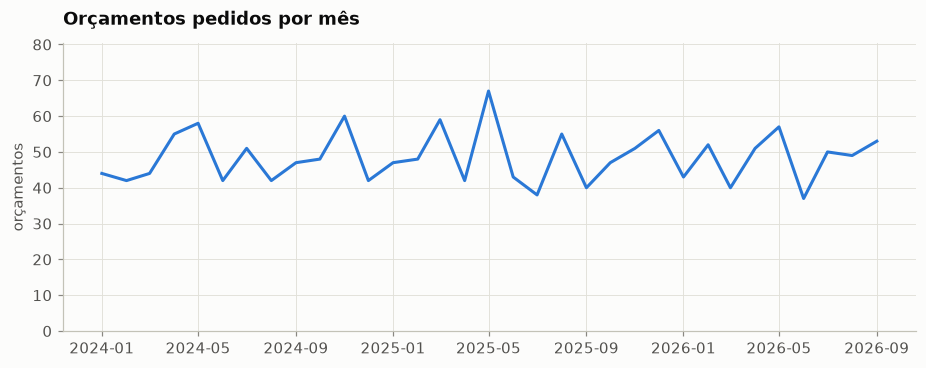

In [12]:
mensal = orcamentos.set_index("data_orcamento").resample("MS")["id_servico"].count()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(mensal.index, mensal.values, color=eg.CORES[0])
ax.set_title("Orçamentos pedidos por mês")
ax.set_ylabel("orçamentos")
ax.set_ylim(0, mensal.max() * 1.2)
plt.show()

A demanda é estável ao longo do período: em média ~49 orçamentos por mês, variando entre 37 e 67, sem tendência
nem sazonalidade forte. Por isso o mês do orçamento não precisa entrar como variável nos modelos.

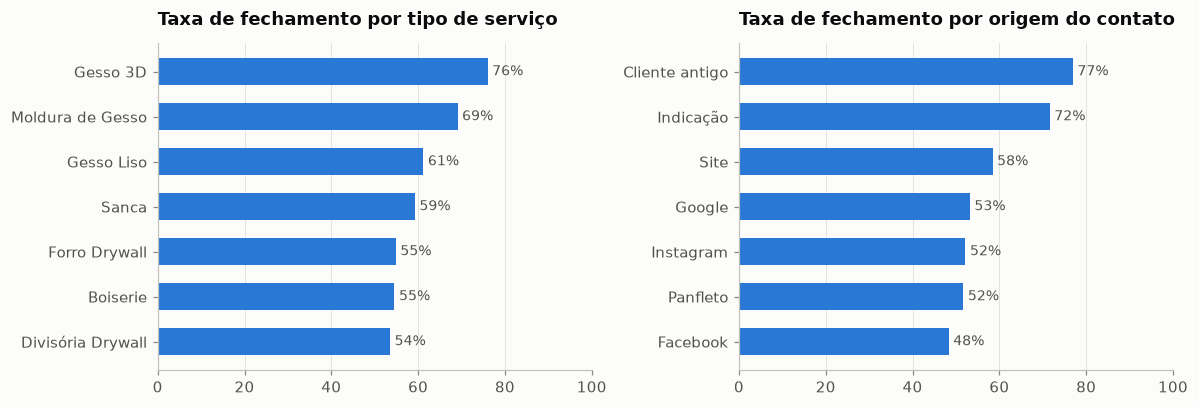

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

por_tipo = decididos.groupby("tipo_servico")["fechou"].mean().sort_values()
barras = axes[0].barh(por_tipo.index, por_tipo.values * 100, color=eg.CORES[0], height=0.6)
eg.rotular_barras(axes[0], barras, "{:.0f}%")
axes[0].set_title("Taxa de fechamento por tipo de serviço")
axes[0].set_xlim(0, 100)
axes[0].grid(axis="y", visible=False)

por_origem = decididos.groupby("origem_contato")["fechou"].mean().sort_values()
barras = axes[1].barh(por_origem.index, por_origem.values * 100, color=eg.CORES[0], height=0.6)
eg.rotular_barras(axes[1], barras, "{:.0f}%")
axes[1].set_title("Taxa de fechamento por origem do contato")
axes[1].set_xlim(0, 100)
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

Já aparecem diferenças (clientes antigos e indicações fecham mais), mas uma análise variável a variável
**não separa causas misturadas**. Por exemplo, quem vem por indicação também costuma receber visita técnica.
Separar esses efeitos é o papel do modelo de classificação no notebook 03.

## 6. Bases geradas

**`dados/processed/orcamentos.csv`**: 1 linha por orçamento:

In [14]:
orcamentos.head()

,id_servico,id_cliente,data_orcamento,mes_orcamento,cidade,origem_contato,tipo_servico,subtipo,grupo_servico,tipo_imovel,unidade_medida,quantidade,valor_tabela,tabela_oficial,valor_referencia,valor_unitario_aplicado,preco_cheio,desconto_pct,preco_a_combinar,valor_total,prazo_retorno_dias,visita_tecnica,n_orcamentos_anteriores,n_fechados_anteriores,cliente_recorrente,data_execucao,status,situacao,fechou
0,1,135,2024-01-03,1,Vargem Grande do Sul,Site,Forro Drywall,,drywall,comercial,metro quadrado,45.11,95.00,1,"4,285.45",88.81,88.81,0,0,"4,006.22",2,1,0,0,0,NaT,sem resposta,perdido,0.00
1,2,29,2024-01-04,1,São João da Boa Vista,Panfleto,Forro Drywall,,drywall,residencial,metro quadrado,3.76,95.00,1,357.20,92.99,92.99,0,0,349.64,3,0,0,0,0,NaT,recusado,perdido,0.00
2,3,160,2024-01-05,1,Mococa,Site,Gesso Liso,Parede Pintada,gesso_liso,industrial,metro quadrado,95.00,22.00,1,"2,090.00",17.72,17.72,0,0,"1,683.40",0,0,0,0,0,2024-02-08,concluído,fechado,1.00
3,4,311,2024-01-05,1,São João da Boa Vista,Google,Gesso Liso,Parede de Tijolo,gesso_liso,comercial,metro quadrado,14.03,30.00,1,420.90,26.18,26.18,0,0,367.31,3,0,0,0,0,NaT,sem resposta,perdido,0.00
4,5,41,2024-01-06,1,Águas da Prata,Facebook,Forro Drywall,,drywall,residencial,metro quadrado,18.45,95.00,1,"1,752.75",98.05,98.05,0,0,"1,809.02",1,0,0,0,0,NaT,recusado,perdido,0.00


**`dados/processed/clientes.csv`**: 1 linha por cliente único, com o comportamento de compra resumido:

In [15]:
clientes.head()

,id_cliente,nome_completo,telefone,email,cidade,origem_contato,data_cadastro,n_orcamentos,n_fechados,ticket_medio,faturamento_total,pct_drywall,pct_decorativo,pct_gesso_liso,pct_residencial,desconto_medio,taxa_conversao,recencia_dias
0,1,Brenda Alves,(35) 93321-8196,NaN,Águas da Prata,Instagram,2023-12-27,3,0,707.75,0.00,0.33,0.67,0.00,1.00,4.00,0.00,569
1,2,Thiago Pereira,(19) 98386-3794,NaN,Espírito Santo do Pinhal,Google,2024-01-30,5,3,"2,677.10","15,936.20",0.60,0.20,0.20,0.00,2.00,0.75,1
2,3,Henrique Teixeira,(16) 91161-5594,NaN,São José do Rio Pardo,Google,2025-09-06,4,1,"4,433.00","1,704.30",0.75,0.25,0.00,0.00,6.25,0.25,104
3,4,Yuri da Rocha,(16) 99310-3413,yuri.rocha78@yahoo.com.br,Águas da Prata,Google,2024-02-23,9,6,"3,044.60","19,939.52",0.78,0.11,0.11,0.00,1.11,0.67,71
4,5,Dr. Gustavo Henrique Rios,(19) 91928-3276,dr..rios6@hotmail.com,Poços de Caldas,Facebook,2024-08-12,2,0,"1,431.32",0.00,0.50,0.50,0.00,1.00,0.00,0.00,705


## Resumo

- Os dados brutos tinham **12 tipos de problema** de qualidade. Todos foram tratados com regras explícitas e reprodutíveis.
- A deduplicação de clientes foi **conferida contra o gabarito** do simulador.
- Resultaram **1.600 orçamentos** e **330 clientes únicos**, prontos para os modelos:
  - [02 · Segmentação de clientes](02_segmentacao_clientes.ipynb) (agrupamento)
  - [03 · Fechamento de orçamentos](03_fechamento_orcamentos.ipynb) (classificação)
  - [04 · Estimativa de preço](04_estimativa_preco.ipynb) (regressão)